### Загрузка исходного датасета

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "data/shopease_raw_orders.csv"
df = pd.read_csv(DATA_PATH)
print(f"Исходный размер датасета: {df.shape[0]} объектов × {df.shape[1]} признаков")

Исходный размер датасета: 10020 объектов × 16 признаков


### Исходные пропуски и статистика Rating

In [5]:
RATING_COL = "Rating"
rating_missing = df[RATING_COL].isna()
rating_mean = df[RATING_COL].mean()

rating_before = pd.DataFrame({
    "Показатель": ["Количество объектов", "Пропусков", "Доля пропусков, %", "Среднее", "Медиана", "Стандартное отклонение"],
    "До обработки": [
        len(df),
        int(rating_missing.sum()),
        round(rating_missing.mean() * 100, 2),
        rating_mean,
        df[RATING_COL].median(),
        df[RATING_COL].std()
    ]
})
display(rating_before)

,Показатель,До обработки
0,Количество объектов,10020.000000
1,Пропусков,2292.000000
2,"Доля пропусков, %",22.870000
3,Среднее,3.958851
4,Медиана,4.000000
5,Стандартное отклонение,1.023657


### Rating: добавление только флага пропуска

In [6]:
df_rating_flag = df.copy()
df_rating_flag["RatingWasMissing"] = df_rating_flag[RATING_COL].isna()

rating_flag_summary = pd.DataFrame({
    "Показатель": ["Количество объектов", "Пропусков в Rating", "Значений с флагом пропуска", "Среднее Rating"],
    "Вариант с флагом": [
        len(df_rating_flag),
        int(df_rating_flag[RATING_COL].isna().sum()),
        int(df_rating_flag["RatingWasMissing"].sum()),
        df_rating_flag[RATING_COL].mean()
    ]
})
display(rating_flag_summary)
print("Значения Rating не заполняются; флаг показывает, где оценка отсутствовала.")

,Показатель,Вариант с флагом
0,Количество объектов,10020.000000
1,Пропусков в Rating,2292.000000
2,Значений с флагом пропуска,2292.000000
3,Среднее Rating,3.958851


Значения Rating не заполняются; флаг показывает, где оценка отсутствовала.


### Rating: заполнение пропусков средним значением

In [7]:
df_rating_mean = df.copy()
df_rating_mean[RATING_COL] = df_rating_mean[RATING_COL].fillna(rating_mean)

rating_mean_summary = pd.DataFrame({
    "Показатель": ["Количество объектов", "Пропусков в Rating", "Среднее", "Медиана", "Стандартное отклонение"],
    "До обработки": [len(df), int(df[RATING_COL].isna().sum()), rating_mean, df[RATING_COL].median(), df[RATING_COL].std()],
    "После заполнения средним": [len(df_rating_mean), int(df_rating_mean[RATING_COL].isna().sum()), df_rating_mean[RATING_COL].mean(), df_rating_mean[RATING_COL].median(), df_rating_mean[RATING_COL].std()]
})
display(rating_mean_summary)

,Показатель,До обработки,После заполнения средним
0,Количество объектов,10020.000000,10020.000000
1,Пропусков в Rating,2292.000000,0.000000
2,Среднее,3.958851,3.958851
3,Медиана,4.000000,4.000000
4,Стандартное отклонение,1.023657,0.898975


### Исходные пропуски и категории PaymentMethod

In [8]:
PAYMENT_COL = "PaymentMethod"
payment_missing = df[PAYMENT_COL].isna()

payment_before = pd.DataFrame({
    "Показатель": ["Количество объектов", "Пропусков", "Доля пропусков, %", "Уникальных непустых категорий"],
    "До обработки": [
        len(df),
        int(payment_missing.sum()),
        round(payment_missing.mean() * 100, 2),
        df[PAYMENT_COL].nunique(dropna=True)
    ]
})
display(payment_before)
display(df[PAYMENT_COL].value_counts(dropna=False).rename("Количество").to_frame())

,Показатель,До обработки
0,Количество объектов,10020.0
1,Пропусков,50.0
2,"Доля пропусков, %",0.5
3,Уникальных непустых категорий,20.0


,Количество
PaymentMethod,
Cash,2012
Visa,1984
Wallet,1941
Mastercard,1930
Bank Transfer,1923
NaN,50
Wallet,17
bank transfer,16
VISA,16


### PaymentMethod: заполнение категорией «Не указано»

In [9]:
df_payment_unknown = df.copy()
df_payment_unknown[PAYMENT_COL] = df_payment_unknown[PAYMENT_COL].fillna("Не указано")

unknown_summary = pd.DataFrame({
    "Показатель": ["Количество объектов", "Пропусков", "Категорий после обработки", "Записей в категории «Не указано»"],
    "После заполнения категорией": [
        len(df_payment_unknown),
        int(df_payment_unknown[PAYMENT_COL].isna().sum()),
        df_payment_unknown[PAYMENT_COL].nunique(),
        int((df_payment_unknown[PAYMENT_COL] == "Не указано").sum())
    ]
})
display(unknown_summary)
display(df_payment_unknown[PAYMENT_COL].value_counts().rename("Количество").to_frame())

,Показатель,После заполнения категорией
0,Количество объектов,10020
1,Пропусков,0
2,Категорий после обработки,21
3,Записей в категории «Не указано»,50


,Количество
PaymentMethod,
Cash,2012
Visa,1984
Wallet,1941
Mastercard,1930
Bank Transfer,1923
Не указано,50
Wallet,17
bank transfer,16
VISA,16


### PaymentMethod: удаление объектов с пропуском

In [10]:
df_payment_dropped = df.dropna(subset=[PAYMENT_COL]).copy()

drop_summary = pd.DataFrame({
    "Показатель": ["Объектов до удаления", "Удалено объектов", "Объектов после удаления", "Пропусков в PaymentMethod после удаления", "Уникальных категорий после удаления"],
    "После удаления строк": [
        len(df),
        len(df) - len(df_payment_dropped),
        len(df_payment_dropped),
        int(df_payment_dropped[PAYMENT_COL].isna().sum()),
        df_payment_dropped[PAYMENT_COL].nunique(dropna=True)
    ]
})
display(drop_summary)
display(df_payment_dropped[PAYMENT_COL].value_counts().rename("Количество").to_frame())

,Показатель,После удаления строк
0,Объектов до удаления,10020
1,Удалено объектов,50
2,Объектов после удаления,9970
3,Пропусков в PaymentMethod после удаления,0
4,Уникальных категорий после удаления,20


,Количество
PaymentMethod,
Cash,2012
Visa,1984
Wallet,1941
Mastercard,1930
Bank Transfer,1923
Wallet,17
bank transfer,16
VISA,16
Mastercard,15


### Сводное сравнение вариантов обработки

In [11]:
comparison = pd.DataFrame([
    {"Признак": "Rating", "Способ": "Добавление флага", "Объектов после обработки": len(df_rating_flag), "Пропусков в признаке": int(df_rating_flag[RATING_COL].isna().sum()), "Дополнительная информация": f"RatingWasMissing отмечает {int(df_rating_flag['RatingWasMissing'].sum())} пропусков; значения Rating сохранены"},
    {"Признак": "Rating", "Способ": "Заполнение средним", "Объектов после обработки": len(df_rating_mean), "Пропусков в признаке": int(df_rating_mean[RATING_COL].isna().sum()), "Дополнительная информация": f"Для заполнения использовано среднее {rating_mean:.2f}"},
    {"Признак": "PaymentMethod", "Способ": "Категория «Не указано»", "Объектов после обработки": len(df_payment_unknown), "Пропусков в признаке": int(df_payment_unknown[PAYMENT_COL].isna().sum()), "Дополнительная информация": f"Создана категория для {int((df_payment_unknown[PAYMENT_COL] == 'Не указано').sum())} пропусков"},
    {"Признак": "PaymentMethod", "Способ": "Удаление строк с пропуском", "Объектов после обработки": len(df_payment_dropped), "Пропусков в признаке": int(df_payment_dropped[PAYMENT_COL].isna().sum()), "Дополнительная информация": f"Удалено {len(df) - len(df_payment_dropped)} объектов"}
])
display(comparison)

,Признак,Способ,Объектов после обработки,Пропусков в признаке,Дополнительная информация
0,Rating,Добавление флага,10020,2292,RatingWasMissing отмечает 2292 пропусков; знач...
1,Rating,Заполнение средним,10020,0,Для заполнения использовано среднее 3.96
2,PaymentMethod,Категория «Не указано»,10020,0,Создана категория для 50 пропусков
3,PaymentMethod,Удаление строк с пропуском,9970,0,Удалено 50 объектов


### Наложенные гистограммы распределения Rating

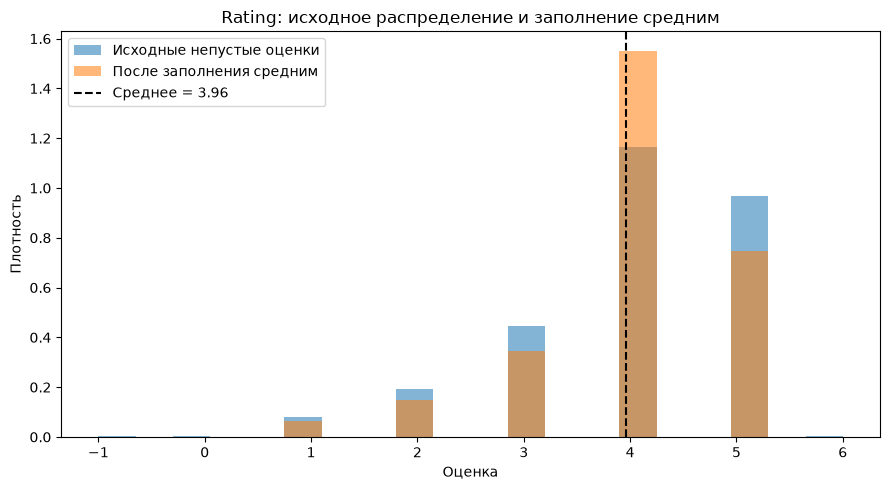

In [14]:
plt.figure(figsize=(9, 5))
plt.hist(df[RATING_COL].dropna(), bins=20, density=True, alpha=0.55, label="Исходные непустые оценки")
plt.hist(df_rating_mean[RATING_COL], bins=20, density=True, alpha=0.55, label="После заполнения средним")
plt.axvline(rating_mean, color="black", linestyle="--", label=f"Среднее = {rating_mean:.2f}")
plt.title("Rating: исходное распределение и заполнение средним")
plt.xlabel("Оценка")
plt.ylabel("Плотность")
plt.legend()
plt.tight_layout()
plt.show()

### Сгруппированная диаграмма долей PaymentMethod

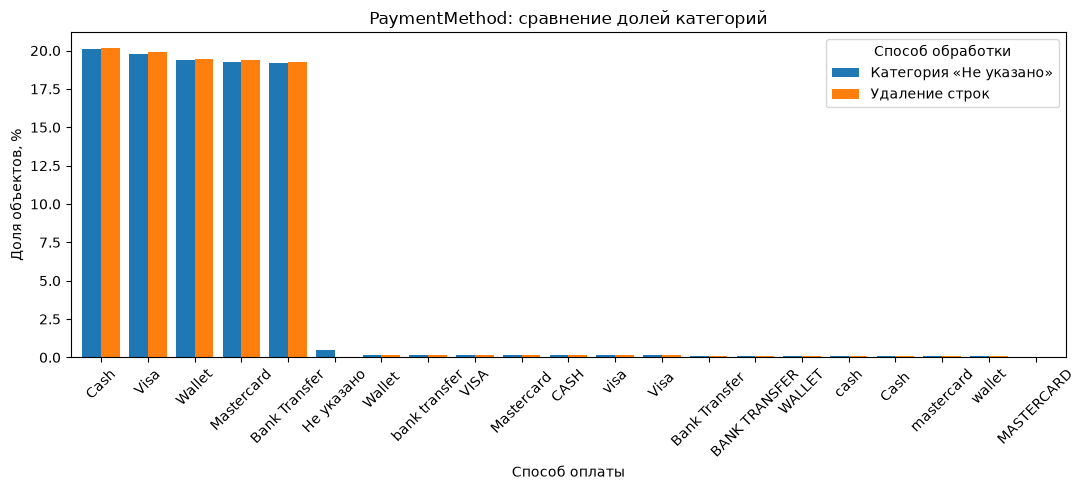

In [15]:
payment_share_unknown = df_payment_unknown[PAYMENT_COL].value_counts(normalize=True).mul(100)
payment_share_dropped = df_payment_dropped[PAYMENT_COL].value_counts(normalize=True).mul(100)
payment_shares = pd.concat([payment_share_unknown.rename("Категория «Не указано»"), payment_share_dropped.rename("Удаление строк")], axis=1).fillna(0)

ax = payment_shares.plot(kind="bar", figsize=(11, 5), width=0.8)
ax.set_title("PaymentMethod: сравнение долей категорий")
ax.set_xlabel("Способ оплаты")
ax.set_ylabel("Доля объектов, %")
ax.legend(title="Способ обработки")
ax.tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.show()